# Beam blockage and the hybrid scan: KDAX (Sacramento), 24 Oct 2021

**Question.** Where terrain cuts off part of the beam, the radar sees too little power and underestimates rain.
Does correcting for it, or switching to a higher tilt where the lowest is blocked, bring the totals closer to
the gauge-corrected reference?

**Case.** The 24 Oct 2021 atmospheric river: widespread, steady rain over northern California. KDAX (S band,
43 m) sits in the Sacramento Valley; the Coast Ranges to the west and the Sierra Nevada foothills to the east
block part of its lowest tilt. 12-16 UTC, the wettest steady hours in MRMS.

**Methods** (all with the brightband VPR correction and motion-following hourly totals of notebooks 02-03):
- blockage per gate from the Copernicus GLO-90 terrain model (`Bech2003BeamBlockage`, Bech et al. 2003),
- *lowest tilt*: as before, blockage ignored,
- *NEXRAD dB correction*: +1 to +4 dB for 11-60 % blockage, nothing above 60 % (Fulton et al. 1998),
- *hybrid scan*: at each place, the lowest tilt that is less than 50 % blocked (`hybrid_scan`),
- *hybrid scan + dB correction*: the same, with the chosen tilt corrected by its blockage (NEXRAD practice).

Reference: MRMS MultiSensor QPE Pass 2 (gauge-corrected); MRMS radar-only as a peer.

In [1]:
# Colab: uncomment to install (downloads ~1 GB of radar data on first run)
!pip install -q cfgrib eccodes pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-core" "git+https://github.com/manmeet3591/radarwow-kdp" "git+https://github.com/manmeet3591/radarwow-attenuation" "git+https://github.com/manmeet3591/radarwow-estimation" "git+https://github.com/manmeet3591/radarwow-classification" "git+https://github.com/manmeet3591/radarwow-verify"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.classification import MeltingLayerTracker, melting_layer_from_volume
from radarwow.core import nexrad_aws_files, open_volume
from radarwow.estimation import (Bech2003BeamBlockage, SyntheticRainRate, ZhangQi2010VPR, ZRRelation, advection_accumulate,
                                 below_melting_layer, copernicus_dem, fulton1998_correction_db, hybrid_scan,
                                 polar_to_cartesian, to_fixed_azimuths, unique_tilts)
from radarwow.kdp import Vulpiani2012KDP
from radarwow.verify import fetch_mrms, hrrr_freezing_level, scores, to_mrms_grid

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "KDAX", "2021-10-24 11:45", "2021-10-24 16:05"
HOURS = [12, 13, 14, 15]
NG, RES, N_TILTS = 600, 1.0, 3

## 1. How much of the beam does the terrain block?

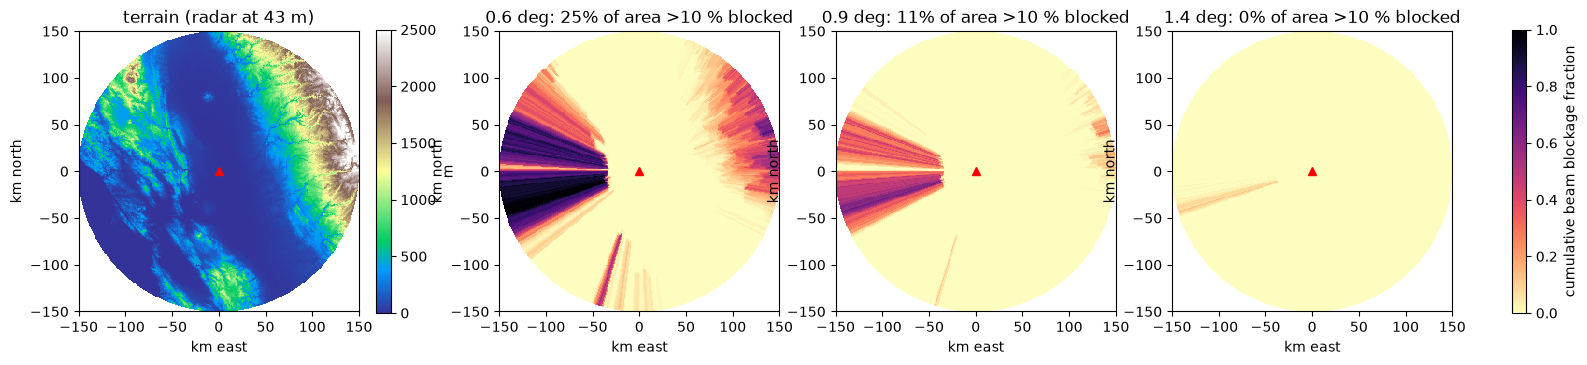

In [3]:
files = nexrad_aws_files(SITE, START, END, cache_dir=f"{CACHE}/nexrad")
dt0 = open_volume(files[0][1], band="S")
lat0, lon0, alt = (float(dt0[k].values) for k in ("latitude", "longitude", "altitude"))
dem = copernicus_dem(lat0, lon0, 160, f"{CACHE}/dem")
bb = Bech2003BeamBlockage(dem=dem, site=(lat0, lon0, alt), beamwidth_deg=0.95)
tilts0 = unique_tilts(dt0)[:N_TILTS]
cbb_cart = []
fig, axes = plt.subplots(1, N_TILTS + 1, figsize=(5.2 * (N_TILTS + 1), 4.6))
for ax, (el, name) in zip(axes[1:], tilts0):
    o = bb(dt0[name].to_dataset().isel(range=slice(0, NG)), band="S")
    c = polar_to_cartesian(to_fixed_azimuths(o["CBB"]), el, max_km=150, res_km=RES)
    cbb_cart.append(c.values)
    m = ax.pcolormesh(c.x, c.y, c, cmap="magma_r", vmin=0, vmax=1, shading="auto")
    ax.set(title=f"{el:.1f} deg: {np.nanmean(c.values > 0.1):.0%} of area >10 % blocked", aspect=1)
fig.colorbar(m, ax=axes[1:], label="cumulative beam blockage fraction", shrink=0.8)
t = polar_to_cartesian(to_fixed_azimuths(o["TERRAIN"]), tilts0[-1][0], max_km=150, res_km=RES)
mt = axes[0].pcolormesh(t.x, t.y, t, cmap="terrain", vmin=0, vmax=2500, shading="auto")
axes[0].set(title=f"terrain (radar at {alt:.0f} m)", aspect=1)
fig.colorbar(mt, ax=axes[0], label="m", shrink=0.8)
for ax in axes:
    ax.plot(0, 0, "r^")
    ax.set(xlabel="km east", ylabel="km north")
fig.savefig(f"{FIG}/10_kdax_blockage.png", dpi=95, bbox_inches="tight")
plt.show()

## 2. Rain rates per tilt, then combined

In [4]:
tracker = MeltingLayerTracker()
fz_cache = {}
METHODS = ["Z-R, lowest tilt", "Z-R, NEXRAD dB correction", "Z-R, hybrid scan", "Z-R, hybrid scan + dB correction", "synthetic, lowest tilt", "synthetic, hybrid scan"]
scans = {k: [] for k in METHODS}
used_tilt = []


def valid_rate(rate, ds, mlb, extra_nan=None):
    """No echo -> 0 mm/h; NaN only where the rate is not valid (above the melting layer, or excluded)."""
    ok = below_melting_layer(ds, ml_bottom_km=mlb)
    if extra_nan is not None:
        ok &= ~extra_nan
    return rate.copy(data=np.where(ok, np.nan_to_num(rate.values), np.nan))


for t, f in files:
    try:
        dt = open_volume(f, band="S")
    except Exception as e:  # noqa: BLE001
        print("skip", t, e)
        continue
    hr = pd.Timestamp(t).round("h")
    if hr not in fz_cache:
        fz_cache[hr] = (hrrr_freezing_level(hr, lat0, lon0, f"{CACHE}/hrrr", 150) - alt) / 1e3
    ml, _ = melting_layer_from_volume(dt)
    use, _ = tracker.update(t, ml, prior_top_km=fz_cache[hr])
    mlb = use.bottom_km if use else fz_cache[hr] - 0.5
    vdt = ZhangQi2010VPR(freezing_level_km=fz_cache[hr])(dt)
    per = {"zr": [], "zr_fulton": [], "syn": [], "cbb": []}
    for el, name in unique_tilts(vdt)[:N_TILTS]:
        ds = bb(vdt[name].to_dataset().isel(range=slice(0, NG)), band="S")
        dsv = ds.assign(DBZH=ds["DBZH_VPR"])
        zr = ZRRelation(preset="marshall_palmer", z_max_dbz=53)(dsv, band="S")["RATE_Z"]
        corr = fulton1998_correction_db(ds["CBB"].values)
        zr_f = ZRRelation(preset="marshall_palmer", z_max_dbz=53)(dsv.assign(DBZH=dsv["DBZH"] + np.nan_to_num(corr)), band="S")["RATE_Z"]
        syn = SyntheticRainRate(temperature_c=15)(Testud2000ZPHI()(Vulpiani2012KDP()(dsv, band="S"), band="S"), band="S")["RATE"]
        cart = lambda da: polar_to_cartesian(to_fixed_azimuths(da), el, max_km=150, res_km=RES).values  # noqa: E731
        per["zr"].append(cart(valid_rate(zr, ds, mlb)))
        per["zr_fulton"].append(cart(valid_rate(zr_f, ds, mlb, extra_nan=np.isnan(corr))))
        per["syn"].append(cart(valid_rate(syn, ds, mlb)))
        per["cbb"].append(cart(ds["CBB"]))
    grid = polar_to_cartesian(to_fixed_azimuths(zr), el, max_km=150, res_km=RES)
    da = lambda v: grid.copy(data=v.astype("float32"))  # noqa: E731
    hz, idx = hybrid_scan(list(zip(per["zr"], per["cbb"])))
    hzf, _ = hybrid_scan(list(zip(per["zr_fulton"], per["cbb"])))
    hs, _ = hybrid_scan(list(zip(per["syn"], per["cbb"])))
    used_tilt.append(idx)
    for k, v in [("Z-R, lowest tilt", per["zr"][0]), ("Z-R, NEXRAD dB correction", per["zr_fulton"][0]), ("Z-R, hybrid scan", hz), ("Z-R, hybrid scan + dB correction", hzf),
                 ("synthetic, lowest tilt", per["syn"][0]), ("synthetic, hybrid scan", hs)]:
        scans[k].append((t, da(v)))
xx, yy = np.meshgrid(grid["x"].values, grid["y"].values)
lat = lat0 + yy / 111.2
lon = lon0 + xx / (111.2 * np.cos(np.deg2rad(lat0)))
dist = np.hypot(xx, yy)
display(Markdown(f"{len(scans[METHODS[0]])} volumes. HRRR 0 C height above the radar: "
                 + ", ".join(f"{k:%H}Z {v:.1f} km" for k, v in fz_cache.items())
                 + f". Hybrid scan used tilt 1 / 2 / 3 for {np.mean(used_tilt[0][dist <= 150] == 0):.0%} / "
                 f"{np.mean(used_tilt[0][dist <= 150] == 1):.0%} / {np.mean(used_tilt[0][dist <= 150] == 2):.0%} of the area."))

43 volumes. HRRR 0 C height above the radar: 12Z 3.5 km, 13Z 3.6 km, 14Z 3.6 km, 15Z 3.6 km, 16Z 3.6 km. Hybrid scan used tilt 1 / 2 / 3 for 86% / 12% / 2% of the area.

## 3. Hourly totals against MRMS, by how blocked the lowest tilt is

In [5]:
c0 = cbb_cart[0]
CLASSES = {"open (<10 %)": c0 < 0.1, "partly blocked (10-50 %)": (c0 >= 0.1) & (c0 < 0.5), "mostly blocked (>50 %)": c0 >= 0.5}
results, cover, maps = [], [], {}
for h in HOURS:
    a, b = pd.Timestamp(f"2021-10-24 {h:02d}:00"), pd.Timestamp(f"2021-10-24 {h + 1:02d}:00")
    ref = fetch_mrms("gauge_corrected", b, f"{CACHE}/mrms")
    ro = fetch_mrms("radar_only", b, f"{CACHE}/mrms")
    vals = {}
    for k in METHODS:
        acc = advection_accumulate(scans[k], a, b)
        vals[k] = np.where((acc["VALID_MINUTES"].values >= 48) & (dist <= 150), acc["ACCUM"].values, np.nan)
        maps[(h, k)] = vals[k]
    maps[(h, "mrms")] = ref
    common = np.logical_and.reduce([np.isfinite(v) for v in vals.values()])
    ones = np.where(dist <= 150, 1.0, np.nan)
    _, ro_all, _ = to_mrms_grid(ones, lat, lon, ro, dist)
    for cname, cmask in CLASSES.items():
        for k in METHODS:
            cover.append(dict(hour=h, method=k, cls=cname, coverage=np.mean(np.isfinite(vals[k][cmask & (dist <= 150)]))))
            o, r_, _ = to_mrms_grid(np.where(common & cmask, vals[k], np.nan), lat, lon, ref, dist)
            results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method=k, cls=cname, **scores(o, r_)))
        o, r_, _ = to_mrms_grid(np.where(common & cmask, 1.0, np.nan), lat, lon, ro, dist)
        _, g_, _ = to_mrms_grid(np.where(common & cmask, 1.0, np.nan), lat, lon, ref, dist)
        results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method="MRMS radar-only", cls=cname, **scores(r_, g_)))
res = pd.DataFrame(results)
cov = pd.DataFrame(cover).groupby(["method", "cls"]).coverage.mean().unstack().round(2)
display(Markdown("**Share of cells with a valid hourly total** (mean of the 4 hours)\n\n" + cov.loc[METHODS].to_markdown()))
order = METHODS + ["MRMS radar-only"]
for cname in CLASSES:
    tab = res[res.cls == cname].pivot_table(index="method", columns="hour", values=["bias_ratio", "corr"]).round(2)
    display(Markdown(f"**{cname}**, cells every method covers (bias = total / MRMS gauge-corrected total)\n\n" + tab.loc[order].to_markdown()))

Pysteps configuration file found at: /Users/manmeet.singh/aircast/radar-wow/.venv/lib/python3.11/site-packages/pysteps/pystepsrc



**Share of cells with a valid hourly total** (mean of the 4 hours)

| method                           |   mostly blocked (>50 %) |   open (<10 %) |   partly blocked (10-50 %) |
|:---------------------------------|-------------------------:|---------------:|---------------------------:|
| Z-R, lowest tilt                 |                     0.99 |              1 |                       0.99 |
| Z-R, NEXRAD dB correction        |                     0.1  |              1 |                       0.99 |
| Z-R, hybrid scan                 |                     0.66 |              1 |                       0.99 |
| Z-R, hybrid scan + dB correction |                     0.66 |              1 |                       0.99 |
| synthetic, lowest tilt           |                     0.99 |              1 |                       0.99 |
| synthetic, hybrid scan           |                     0.66 |              1 |                       0.99 |

**open (<10 %)**, cells every method covers (bias = total / MRMS gauge-corrected total)

| method                           |   ('bias_ratio', '12-13') |   ('bias_ratio', '13-14') |   ('bias_ratio', '14-15') |   ('bias_ratio', '15-16') |   ('corr', '12-13') |   ('corr', '13-14') |   ('corr', '14-15') |   ('corr', '15-16') |
|:---------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| Z-R, lowest tilt                 |                      0.52 |                      0.49 |                      0.51 |                      0.54 |                0.81 |                0.85 |                0.86 |                0.85 |
| Z-R, NEXRAD dB correction        |                      0.52 |                      0.49 |                      0.51 |                      0.54 |                0.81 |                0.85 |                0.85 |                0.85 |
| Z-R, hybrid scan                 |                      0.52 |                      0.49 |                      0.51 |                      0.54 |                0.81 |                0.85 |                0.86 |                0.85 |
| Z-R, hybrid scan + dB correction |                      0.52 |                      0.49 |                      0.51 |                      0.54 |                0.82 |                0.85 |                0.86 |                0.85 |
| synthetic, lowest tilt           |                      0.53 |                      0.5  |                      0.52 |                      0.55 |                0.82 |                0.85 |                0.86 |                0.86 |
| synthetic, hybrid scan           |                      0.53 |                      0.5  |                      0.52 |                      0.55 |                0.82 |                0.85 |                0.86 |                0.86 |
| MRMS radar-only                  |                      0.66 |                      0.64 |                      0.68 |                      0.7  |                0.92 |                0.91 |                0.93 |                0.92 |

**partly blocked (10-50 %)**, cells every method covers (bias = total / MRMS gauge-corrected total)

| method                           |   ('bias_ratio', '12-13') |   ('bias_ratio', '13-14') |   ('bias_ratio', '14-15') |   ('bias_ratio', '15-16') |   ('corr', '12-13') |   ('corr', '13-14') |   ('corr', '14-15') |   ('corr', '15-16') |
|:---------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| Z-R, lowest tilt                 |                      0.39 |                      0.35 |                      0.36 |                      0.35 |                0.53 |                0.56 |                0.71 |                0.8  |
| Z-R, NEXRAD dB correction        |                      0.47 |                      0.42 |                      0.42 |                      0.43 |                0.53 |                0.55 |                0.71 |                0.82 |
| Z-R, hybrid scan                 |                      0.39 |                      0.35 |                      0.36 |                      0.35 |                0.53 |                0.56 |                0.71 |                0.8  |
| Z-R, hybrid scan + dB correction |                      0.47 |                      0.42 |                      0.42 |                      0.43 |                0.53 |                0.55 |                0.72 |                0.82 |
| synthetic, lowest tilt           |                      0.4  |                      0.36 |                      0.37 |                      0.36 |                0.54 |                0.57 |                0.71 |                0.81 |
| synthetic, hybrid scan           |                      0.4  |                      0.36 |                      0.37 |                      0.36 |                0.54 |                0.57 |                0.71 |                0.81 |
| MRMS radar-only                  |                      0.53 |                      0.47 |                      0.48 |                      0.46 |                0.84 |                0.85 |                0.83 |                0.89 |

**mostly blocked (>50 %)**, cells every method covers (bias = total / MRMS gauge-corrected total)

| method                           |   ('bias_ratio', '12-13') |   ('bias_ratio', '13-14') |   ('bias_ratio', '14-15') |   ('bias_ratio', '15-16') |   ('corr', '12-13') |   ('corr', '13-14') |   ('corr', '14-15') |   ('corr', '15-16') |
|:---------------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| Z-R, lowest tilt                 |                      0.25 |                      0.25 |                      0.29 |                      0.29 |                0.74 |                0.71 |                0.76 |                0.81 |
| Z-R, NEXRAD dB correction        |                      0.38 |                      0.38 |                      0.44 |                      0.43 |                0.75 |                0.73 |                0.77 |                0.81 |
| Z-R, hybrid scan                 |                      0.3  |                      0.29 |                      0.33 |                      0.34 |                0.77 |                0.75 |                0.82 |                0.88 |
| Z-R, hybrid scan + dB correction |                      0.36 |                      0.35 |                      0.41 |                      0.41 |                0.76 |                0.72 |                0.77 |                0.87 |
| synthetic, lowest tilt           |                      0.25 |                      0.26 |                      0.3  |                      0.3  |                0.75 |                0.72 |                0.77 |                0.82 |
| synthetic, hybrid scan           |                      0.3  |                      0.29 |                      0.33 |                      0.35 |                0.78 |                0.75 |                0.83 |                0.88 |
| MRMS radar-only                  |                      0.43 |                      0.41 |                      0.41 |                      0.43 |                0.83 |                0.85 |                0.87 |                0.88 |

Every method underestimates even where nothing is blocked (see the takeaways). To separate the blockage effect
from that, divide each class's bias by the same method's bias over open terrain in the same hour: 1.00 means
the blocked area is estimated as well as the open area.

In [6]:
b = res.pivot_table(index=["method", "hour"], columns="cls", values="bias_ratio")
rel = pd.DataFrame({c: b[c] / b["open (<10 %)"] for c in ["partly blocked (10-50 %)", "mostly blocked (>50 %)"]})
rel = rel.groupby("method").mean().round(2)
display(Markdown("**Bias relative to open terrain** (mean of the 4 hours)\n\n" + rel.loc[order].to_markdown()))

**Bias relative to open terrain** (mean of the 4 hours)

| method                           |   partly blocked (10-50 %) |   mostly blocked (>50 %) |
|:---------------------------------|---------------------------:|-------------------------:|
| Z-R, lowest tilt                 |                       0.71 |                     0.53 |
| Z-R, NEXRAD dB correction        |                       0.85 |                     0.79 |
| Z-R, hybrid scan                 |                       0.71 |                     0.61 |
| Z-R, hybrid scan + dB correction |                       0.85 |                     0.74 |
| synthetic, lowest tilt           |                       0.71 |                     0.53 |
| synthetic, hybrid scan           |                       0.71 |                     0.61 |
| MRMS radar-only                  |                       0.72 |                     0.63 |

## 4. One hour, mapped

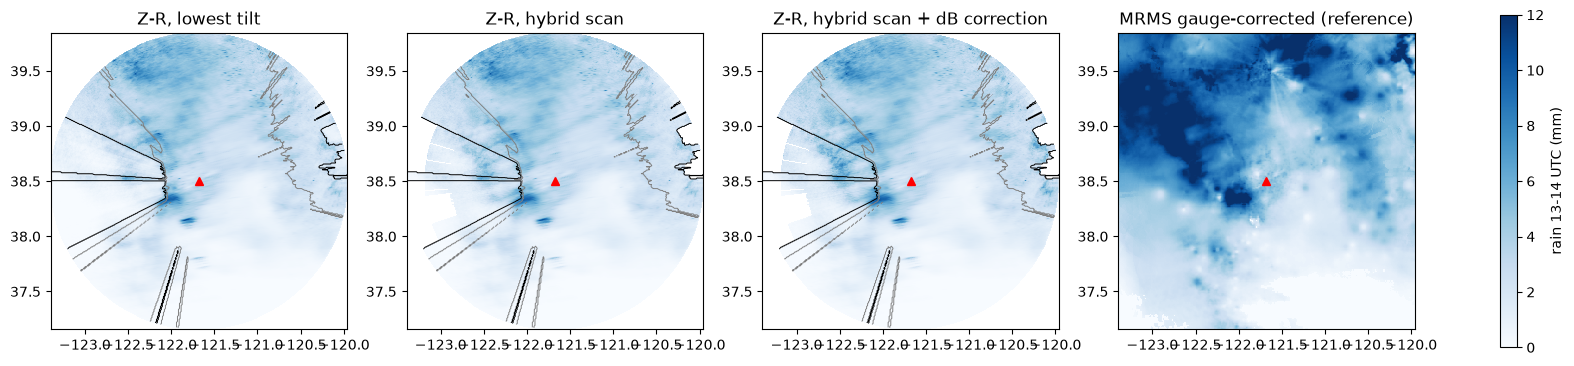

In [7]:
h = 13
ref = maps[(h, "mrms")]
fig, axes = plt.subplots(1, 4, figsize=(22, 5.4))
kw = dict(cmap="Blues", vmin=0, vmax=12, shading="auto")
for ax, k in zip(axes[:3], ["Z-R, lowest tilt", "Z-R, hybrid scan", "Z-R, hybrid scan + dB correction"]):
    m = ax.pcolormesh(lon, lat, np.ma.masked_invalid(maps[(h, k)]), **kw)
    ax.contour(lon, lat, c0, levels=[0.1, 0.5], colors=["0.5", "k"], linewidths=0.7)
    ax.set_title(k)
box = ref.sel(latitude=slice(lat.max(), lat.min()), longitude=slice(lon.min(), lon.max()))
axes[3].pcolormesh(box.longitude, box.latitude, np.ma.masked_invalid(box.values), **kw)
axes[3].set_title("MRMS gauge-corrected (reference)")
for ax in axes:
    ax.set(xlim=(lon.min(), lon.max()), ylim=(lat.min(), lat.max()), aspect=1 / np.cos(np.deg2rad(lat0)))
    ax.plot(lon0, lat0, "r^")
fig.colorbar(m, ax=axes, label=f"rain {h:02d}-{h + 1:02d} UTC (mm)", shrink=0.8)
fig.savefig(f"{FIG}/11_kdax_maps_{h:02d}.png", dpi=90, bbox_inches="tight")
plt.show()

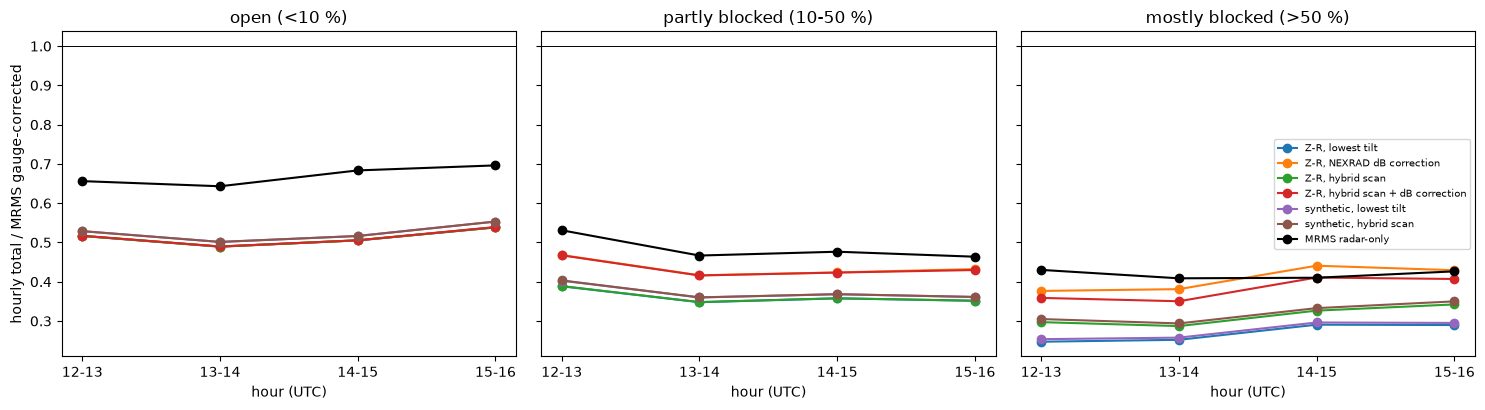

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, cname in zip(axes, CLASSES):
    r = res[res.cls == cname]
    for i, k in enumerate(order):
        g = r[r.method == k].sort_values("hour")
        ax.plot(g.hour, g.bias_ratio, "o-", color="k" if "MRMS" in k else f"C{i}", label=k)
    ax.axhline(1, color="k", lw=0.7)
    ax.set(title=cname, xlabel="hour (UTC)")
axes[0].set_ylabel("hourly total / MRMS gauge-corrected")
axes[2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/12_kdax_bias_by_blockage.png", dpi=110)
plt.show()

## Takeaways
- **The blockage map is physical.** At 0.6 deg the Vaca Mountains block everything to the west beyond ~35 km,
  Mount Diablo casts a narrow shadow to the south-south-west, and the Sierra foothills block patches to the east:
  25 % of the area within 150 km is more than 10 % blocked. At 0.9 deg it is 11 %, at 1.4 deg almost nothing.
- **Blockage costs rain where you'd expect.** Relative to open terrain in the same hour, the lowest tilt gets
  0.71 of the rain in partly blocked areas and 0.53 in mostly blocked ones.
- **Hybrid scan plus the NEXRAD dB correction closes about half of that gap** (0.85 and 0.74), better than MRMS
  radar-only on the same cells (0.72 and 0.63). The hybrid scan alone does nothing in partly blocked areas, by
  design: the lowest tilt is kept while it is under 50 % blocked. The dB correction alone is good where it applies
  but leaves 90 % of the mostly blocked area empty (it gives up above 60 %). Combined, the higher tilt fills those
  gaps and the dB correction handles the rest; coverage of the mostly blocked area is 66 % (the rest is blocked
  or above the melting layer on all three tilts).
- **Part of the remaining gap may not be blockage.** The blocked areas are the mountains, where rain grows below the
  beam as air is lifted over the terrain and the gauge-corrected reference is higher; a higher tilt sees even less
  of that low-level growth.
- **The bigger problem in this case is not blockage: every method underestimates by about half even in the open
  valley** (bias 0.49-0.55; MRMS radar-only 0.64-0.70). Atmospheric-river rain is dominated by many small drops,
  for which Marshall-Palmer gives too little rain at a given Z. The synthetic estimate does not help here because
  R(A) needs at least 40 deg of differential phase along the ray, rarely reached in this moderate rain. Next steps:
  a rain-type-aware Z-R (or R(Z, ZDR)), and checking KDAX's reflectivity calibration.
- **Assumptions:** standard 4/3-Earth refraction and exact antenna pointing (Bech et al.: 0.1 deg pointing error is
  ~10 % blockage); 90 m terrain without buildings or trees; one case.